# Questions 5.1 to 5.8

### Imports

In [1]:
import config as cfg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import src.loading as ld
import src.normalise as norm
import src.features as ftrs
import src.selection as sel
import src.evaluation as evl
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.feature_selection import SelectKBest, f_classif
from scipy.stats import wilcoxon
from sklearn.base import clone

### Loading Development Data
Only the 20 development actors are loaded (`include_tests=False`). The test actors are loaded in 5.7 only.

In [2]:
df = ld.load_frames()
df_n = norm.normalise_d(df)
feature_table = ftrs.build_feature_table(df_n)

feature_names = feature_table.columns.tolist()
X = feature_table.to_numpy()
y = feature_table.index.get_level_values("emotion").to_numpy()
groups = feature_table.index.get_level_values("actor").to_numpy()

X_base = ftrs.build_feature_table(df_n, own=False).to_numpy()

### Helper Function & LOSO Procedure

In [3]:
loso_results, n_features = {}, {}

def run_loso(name, pipe, n_feat, X_data=X):
    loso_results[name] = evl.evaluation(X_data, y, LeaveOneGroupOut(), pipe, groups)[0]
    n_features[name] = str(n_feat)

def results_table(names):
    return pd.DataFrame({name: {"features": n_features[name],
                                "macro F1 mean": loso_results[name]["macro_f1"].mean(),
                                "macro F1 std": loso_results[name]["macro_f1"].std(),
                                "accuracy mean": loso_results[name]["accuracy"].mean()}
                         for name in names}).T.round(4)

pipe_all = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])
run_loso("All (55)", pipe_all, 55)
run_loso("Base (30)", clone(pipe_all), 30, X_data=X_base)

## 5.1

### Standardising the features
The features have different units and scales (for example, a mean in units of d and an energy in units of d² per frame²), so they are standardised before the PCA: every feature gets mean 0 and standard deviation 1. For exploration only, the scaler and the PCA are fitted on all 1200 development videos; no score is computed in 5.1.

In [4]:
scaler = StandardScaler()
Z = scaler.fit_transform(feature_table)

print(Z.shape)

(1200, 55)


### PCA

In [5]:
pca = PCA()
pca.fit(Z)
scores = pca.transform(Z) # coordinates of each video on the components

cumulative = np.cumsum(pca.explained_variance_ratio_)
n_75 = np.argmax(cumulative >= 0.75) + 1 # first component that reaches 75 %
n_95 = np.argmax(cumulative >= 0.95) + 1

print(f"Components for 75 % of the variance: {n_75}")
print(f"Components for 95 % of the variance: {n_95}")

Components for 75 % of the variance: 8
Components for 95 % of the variance: 23


In [6]:
variance_table = pd.DataFrame({"explained": pca.explained_variance_ratio_,
                               "cumulative": cumulative},
                              index=[f"PC{i + 1}" for i in range(len(cumulative))])
variance_table.head(10).round(3)

,explained,cumulative
PC1,0.365,0.365
PC2,0.133,0.498
PC3,0.070,0.567
PC4,0.057,0.625
PC5,0.043,0.668
PC6,0.038,0.706
PC7,0.035,0.740
PC8,0.027,0.767
PC9,0.024,0.791
PC10,0.023,0.814


**Table: explained variance of the first 10 components.** Share of the total variance explained by each component and cumulative share, out of 55 components.

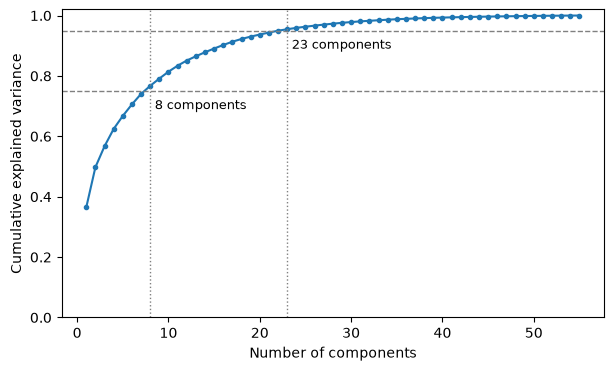

In [7]:
n_components = np.arange(1, len(cumulative) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_components, cumulative, marker="o", markersize=3)

for level, n in [(0.75, n_75), (0.95, n_95)]:
    ax.axhline(level, color="grey", linestyle="--", linewidth=1)
    ax.axvline(n, color="grey", linestyle=":", linewidth=1)
    ax.text(n + 0.5, level - 0.06, f"{n} components", fontsize=9)

ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_ylim(0, 1.02)
plt.show()

**Figure: cumulative explained variance.** Cumulative share of the variance against the number of components kept. Dashed lines: 75 % and 95 % of the variance; dotted lines: the number of components that first reaches each of them.

In [8]:
measure_shares = sel.loadings_by_measure(pca, feature_table.columns, n_components=2)
measure_shares.round(3)

,PC1,PC2
M1,0.127,0.106
M2,0.130,0.041
M3,0.120,0.016
M4,0.043,0.255
M5,0.022,0.208
M6,0.053,0.070
own_M7,0.128,0.019
own_M8,0.124,0.104
own_M9,0.057,0.095
own_M10,0.123,0.016


**Table: share of PC1 and PC2 by measure.** For each component, the squared loadings of the five statistics of a measure are summed. The squared loadings of one component add up to 1, so each column adds up to 1 and each value is the share of that component that comes from the measure.

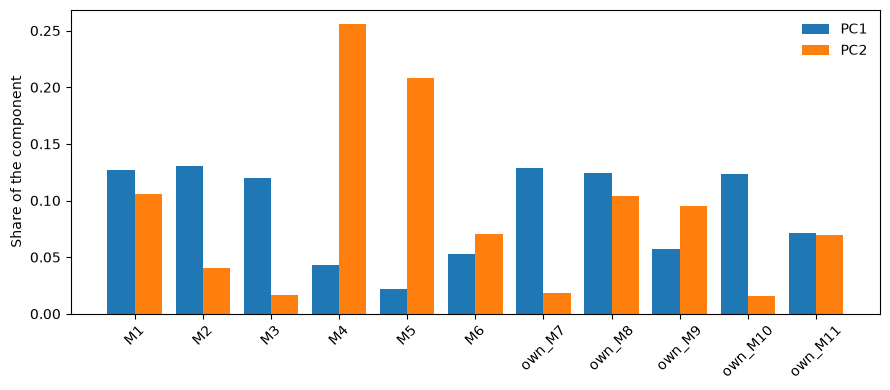

In [9]:
positions = np.arange(len(measure_shares))
width = 0.4

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(positions - width / 2, measure_shares["PC1"], width, label="PC1")
ax.bar(positions + width / 2, measure_shares["PC2"], width, label="PC2")
ax.set_xticks(positions)
ax.set_xticklabels(measure_shares.index, rotation=45)
ax.set_ylabel("Share of the component")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Figure: share of PC1 and PC2 by measure.** The values of the table above, one bar per measure and component.

In [10]:
loadings = sel.loadings_table(pca, feature_table.columns, n_components=2)

top_pc1 = loadings["PC1"].sort_values(key=abs, ascending=False).head(10)
top_pc2 = loadings["PC2"].sort_values(key=abs, ascending=False).head(10)

top_loadings = pd.DataFrame({"PC1 feature": top_pc1.index, "PC1 loading": top_pc1.values,
                             "PC2 feature": top_pc2.index, "PC2 loading": top_pc2.values})
top_loadings.round(3)

,PC1 feature,PC1 loading,PC2 feature,PC2 loading
0,M2_vel,0.197,M4_vel,0.252
1,M3_vel,0.195,M4_range,0.247
2,own_M7_vel,0.194,M4_std,0.238
3,own_M10_vel,0.194,M5_std,0.236
4,M2_range,0.185,M5_vel,0.228
5,own_M7_range,0.180,M5_range,0.227
6,own_M8_vel,0.180,M4_energy,0.219
7,M1_vel,0.178,M5_energy,0.213
8,own_M7_energy,0.176,own_M9_range,0.170
9,own_M10_energy,0.175,M1_energy,-0.170


**Table: the 10 features with the largest loadings on PC1 and on PC2.** Loadings with their sign, ordered by absolute value. The sign of a component is arbitrary: only the relative signs within a component matter.

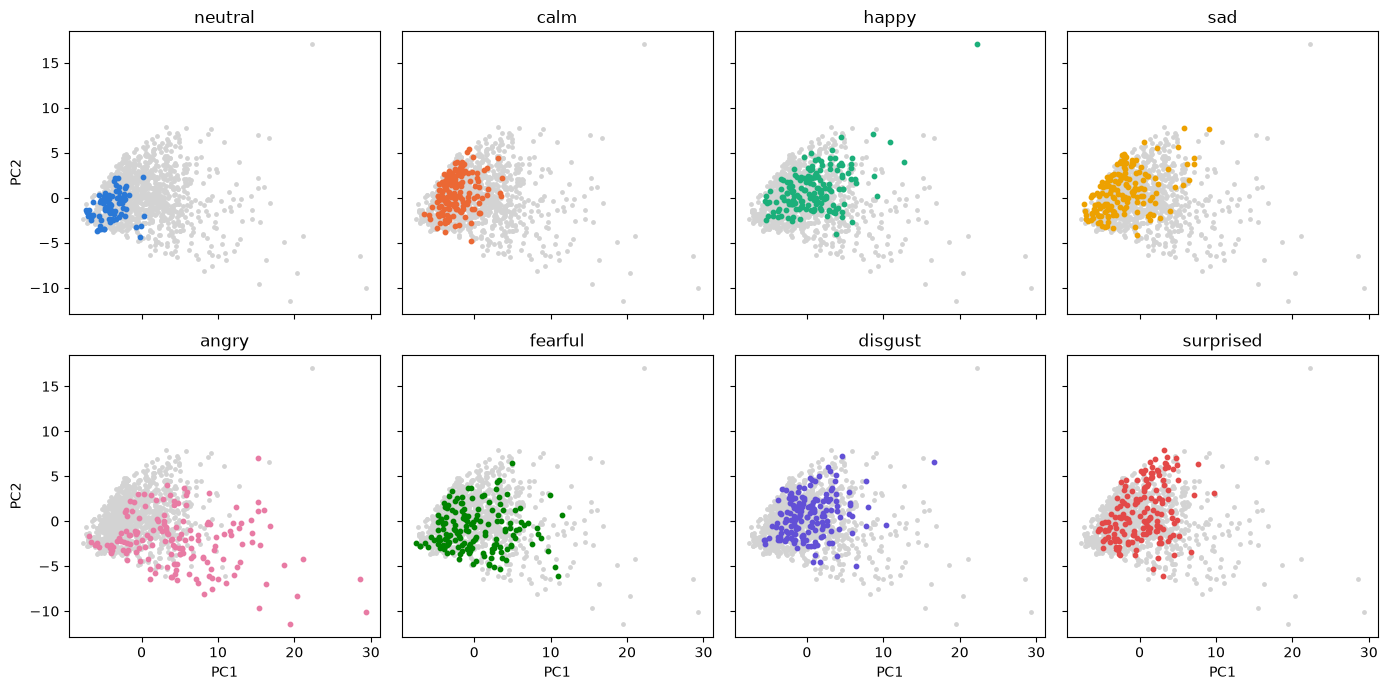

In [11]:
emotion_codes = feature_table.index.get_level_values("emotion")
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)

for i, (emotion_code, name) in enumerate(cfg.EMOTIONS.items()):
    ax = axes.flat[i]
    is_emotion = emotion_codes == emotion_code

    ax.scatter(scores[~is_emotion, 0], scores[~is_emotion, 1], s=6, color="lightgrey")
    ax.scatter(scores[is_emotion, 0], scores[is_emotion, 1], s=10, color=colors[i])
    ax.set_title(name)

for ax in axes[1]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

**Figure: the development videos on the first two components, by emotion.** Each panel highlights the videos of one emotion; the grey points are the videos of the other seven emotions. All panels share the same axes.

### Answer 5.1

Of the 55 components, 8 are needed to explain 75 % of the variance and 23 to explain 95 %. PC1 alone explains 36.5 % and PC2 13.3 %. A few components hold most of the variance because many features are strongly correlated with each other, as found in 3.4.

PC1 is spread over the six mouth measures, M1, M2, M3, own_M7, own_M8 and own_M10, each with about 12 to 13 % of the component and about 75 % together; no single measure dominates it. Its ten largest loadings have the same sign and are all `vel`, `range` or `energy` features, none of them a `mean`: PC1 grows with the amount of mouth movement in the video, not with the average shape of the mouth. PC2 is dominated by the eye and brow measures M4 (25.5 %) and M5 (20.8 %), and its largest loadings are again their movement features (`vel`, `range`, `std`, `energy`), with `M1_energy` as the only negative one in its top ten.

On the first two components the emotions overlap strongly. Neutral and calm stay in a compact region at low PC1, while angry is the only emotion that spreads far along PC1, towards negative PC2. The components are chosen without the emotion labels, to keep as much variance as possible, so two of them not separating the eight emotions does not really show that the 55 features cannot separate them.

## 5.2

### Pipelines
Three pipelines are evaluated under LOSO, all with `SVC(C=1)`, the value of `C_FIXED` chosen in 4.6:

- `StandardScaler → SVC`, with all 55 features;
- `StandardScaler → PCA(0.75) → SVC`, keeping the smallest number of components that explains 75 % of the variance;
- `StandardScaler → PCA(0.95) → SVC`, the same with 95 %.

Unlike 5.1, the scaler and the PCA are steps of the pipeline: in each of the 20 folds they are fitted on the 19 training actors only, and the held-out actor is only transformed.

In [12]:
pipe_pca75 = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=0.75)), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])
pipe_pca95 = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=0.95)), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])

run_loso("PCA 75 %", pipe_pca75, "?")
run_loso("PCA 95 %", pipe_pca95, "?")

per_fold_all = loso_results["All (55)"]
per_fold_pca75 = loso_results["PCA 75 %"]
per_fold_pca95 = loso_results["PCA 95 %"]

### Components kept in each fold

In [13]:
components_75 = sel.pca_components_per_fold(X, y, groups, 0.75)
components_95 = sel.pca_components_per_fold(X, y, groups, 0.95)

for name, comps in [("PCA 75 %", components_75), ("PCA 95 %", components_95)]:
    lo, hi = comps["n_components"].min(), comps["n_components"].max()
    n_features[name] = str(lo) if lo == hi else f"{lo}–{hi}"

pd.DataFrame({"PCA 75 %": components_75["n_components"].value_counts().sort_index(),
              "PCA 95 %": components_95["n_components"].value_counts().sort_index()}).fillna(0).astype(int)

,PCA 75 %,PCA 95 %
n_components,,
8,20,0
22,0,13
23,0,7


**Table: number of components kept, counted over the 20 folds.** Each row is a number of components and each value is the number of folds in which the PCA, fitted on the 19 training actors, kept that number.

### Macro F1 of the three pipelines

In [14]:
pca_results = pd.DataFrame({"all 55 features": per_fold_all["macro_f1"].agg(["mean", "std"]),
                            "PCA 75 %": per_fold_pca75["macro_f1"].agg(["mean", "std"]),
                            "PCA 95 %": per_fold_pca95["macro_f1"].agg(["mean", "std"])}).T
pca_results.round(4)

,mean,std
all 55 features,0.5574,0.1460
PCA 75 %,0.4625,0.1348
PCA 95 %,0.5385,0.1510


**Table: LOSO macro F1 of the three pipelines.** Mean and standard deviation over the 20 held-out development actors, with `C = 1`.

### Paired comparison with all the features

In [15]:
diff_75 = per_fold_pca75["macro_f1"].values - per_fold_all["macro_f1"].values
diff_95 = per_fold_pca95["macro_f1"].values - per_fold_all["macro_f1"].values

paired_rows_pca = list()
for name, diff in [("PCA 75 % - all", diff_75), ("PCA 95 % - all", diff_95)]:
    paired_rows_pca.append({"comparison": name,
                        "mean difference": diff.mean(),
                        "std of the differences": diff.std(ddof=1),
                        "actors improved": int((diff > 0).sum()),
                        "actors worse": int((diff < 0).sum())})

pd.DataFrame(paired_rows_pca).set_index("comparison").round(4)

,mean difference,std of the differences,actors improved,actors worse
comparison,,,,
PCA 75 % - all,-0.0949,0.0887,3,17
PCA 95 % - all,-0.0190,0.0452,5,15


**Table: paired differences in macro F1, PCA minus all features.** For each held-out actor, the macro F1 of the PCA pipeline minus the macro F1 with all 55 features; mean and standard deviation of the 20 differences, and the number of actors with a higher or a lower score.

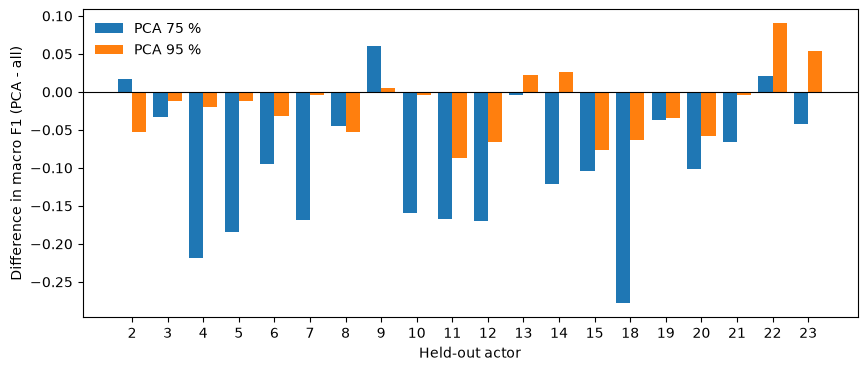

In [16]:
actors = per_fold_all["held_out_actor"].astype(str)
positions = np.arange(len(actors))
width = 0.4

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(positions - width / 2, diff_75, width, label="PCA 75 %")
ax.bar(positions + width / 2, diff_95, width, label="PCA 95 %")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels(actors)
ax.set_xlabel("Held-out actor")
ax.set_ylabel("Difference in macro F1 (PCA - all)")
ax.legend(frameon=False)
plt.show()

**Figure: difference in macro F1 per held-out actor, PCA minus all features.** One pair of bars per actor; bars below zero are actors whose score is lower with the PCA pipeline.

### Answer to Q5.2

Compressing the representation does not help the classifier. With all 55 features the LOSO macro F1 is 0.557 ± 0.146. Keeping 95 % of the variance (22 or 23 components, depending on the fold) gives 0.539 ± 0.151, and keeping 75 % (8 components in every fold) gives 0.463 ± 0.135.

Because the three pipelines are tested on the same actors, the fairer comparison is paired. With 95 % the loss is small, 0.019 on average with a standard deviation of 0.044, but 15 of the 20 actors get a lower score. With 75 % the loss is 0.095, with a standard deviation of 0.087, and 17 of the 20 actors get a lower score: here the loss is clearly larger than the variation between actors.

**Why.** PCA only rotates the standardised features: with all 55 components the distances between videos are the same as without PCA, and the RBF SVC depends only on those distances. What changes the model is dropping the last components. PCA orders the components by variance without looking at the emotion labels, so a direction with little variance is dropped even if it is the one that separates two emotions. As seen in 5.1, the largest components follow the amount of movement in the video, and the subtle differences, for example between neutral, calm and sad (4.4), may lie in the components with less variance. The 25 % of variance dropped at 75 % clearly holds information about the emotion; the 5 % dropped at 95 % holds a little. With 1200 videos and 55 features, the SVC with `C = 1` does not need fewer dimensions, so the compression removes information and gives nothing in exchange.

## 5.3 Univariate Selection (ANOVA F-statistic)

In [17]:
for K in cfg.K_GRID:
    pipe = Pipeline([("scaler", StandardScaler()), ("select", SelectKBest(f_classif, k=K)), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])
    run_loso(f"ANOVA K={K}", pipe, K)

results_table(["All (55)"] + [f"ANOVA K={K}" for K in cfg.K_GRID])

,features,macro F1 mean,macro F1 std,accuracy mean
All (55),55,0.557425,0.145965,0.589167
ANOVA K=5,5,0.345485,0.127188,0.404167
ANOVA K=10,10,0.421546,0.11408,0.480833
ANOVA K=15,15,0.4286,0.129257,0.483333


With `SelectKBest(f_classif)` being a step of the pipeline, in every LOSO fold the F-statistic is computed on the 19 training actors only. The held-out actor takes no part in which features are kept.

With 15 features the macro F1 is ~0.13 below the 55 features. Going from 10 to 15 features adds only 0.007, so the 5 extra features bring almost no new information.

Our takeaways, linking to what we saw in previous notebooks:
- **The information is spread over many features.** In 3.3, no feature separates more than one or two emotions, so the classifier needs many weak features together. Removing features from this model removes information rather than noise.
- **The F-statistic scores each feature alone.** Features that carry the same information get similar scores and take places together (3.4).

## 5.4 mRMR Selection

In [18]:
for K in cfg.K_GRID:
    pipe = Pipeline([("scaler", StandardScaler()), ("select", evl.MRMRSelector(K=K)), ("svc", SVC(kernel="rbf", C=cfg.C_FIXED))])
    run_loso(f"mRMR K={K}", pipe, K)

results_table(["All (55)"] + [f"{m} K={K}" for K in cfg.K_GRID for m in ("ANOVA", "mRMR")])

,features,macro F1 mean,macro F1 std,accuracy mean
All (55),55,0.557425,0.145965,0.589167
ANOVA K=5,5,0.345485,0.127188,0.404167
mRMR K=5,5,0.365749,0.156925,0.421667
ANOVA K=10,10,0.421546,0.11408,0.480833
mRMR K=10,10,0.462224,0.15234,0.5175
ANOVA K=15,15,0.4286,0.129257,0.483333
mRMR K=15,15,0.493576,0.138554,0.540833


### Comparison Table (mRMR vs ANOVA)

In [19]:
paired_rows = {}
for K in cfg.K_GRID:
    diff = loso_results[f"mRMR K={K}"]["macro_f1"].values - loso_results[f"ANOVA K={K}"]["macro_f1"].values
    paired_rows[f"K={K}"] = pd.Series({"Mean Difference (mRMR - ANOVA)": round(diff.mean(), 4),
                                       "STD of the Differences": round(diff.std(ddof=1), 4),
                                       "Actors Improved": int((diff > 0).sum()),
                                       "Wilcoxon p-value": round(wilcoxon(diff).pvalue, 4)}, 
                                      dtype=object)
pd.DataFrame(paired_rows)

,K=5,K=10,K=15
Mean Difference (mRMR - ANOVA),0.0203,0.0407,0.065
STD of the Differences,0.0911,0.0982,0.1024
Actors Improved,11,13,15
Wilcoxon p-value,0.4304,0.0897,0.0073


The paired comparison shows that the gain is within the variation between actors for K = 5 (11 of 20 actors improve, p = 0.43) and K = 10 (13 of 20, p = 0.09)\
Only for K = 15 is it clearly larger (15 of 20, p = 0.007).

### Visualization of the Comparison Between Macro F1

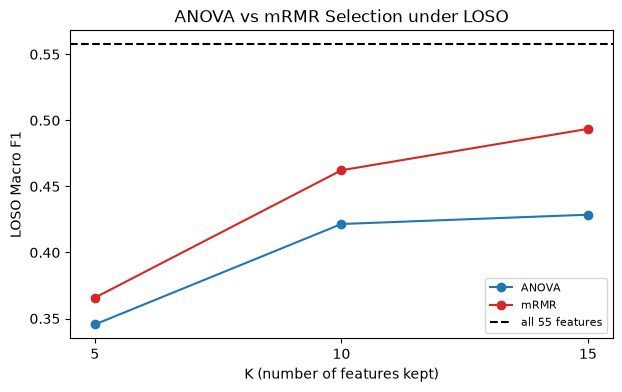

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
for method, color in [("ANOVA", "tab:blue"), ("mRMR", "tab:red")]:
    means = [loso_results[f"{method} K={K}"]["macro_f1"].mean() for K in cfg.K_GRID]
    ax.plot(cfg.K_GRID, means, marker="o", color=color, label=method)
ax.axhline(loso_results["All (55)"]["macro_f1"].mean(), color="black", linestyle="--", label="all 55 features")
ax.set_xticks(cfg.K_GRID)
ax.set_xlabel("K (number of features kept)")
ax.set_ylabel("LOSO Macro F1")
ax.set_title("ANOVA vs mRMR Selection under LOSO")
ax.legend(fontsize=8)
plt.show()

### Answer 5.4

mRMR is wrapped in a transformer (`MRMRSelector`), so, like `SelectKBest`, it is a step of the pipeline and is refitted on the 19 training actors of each LOSO fold.

mRMR is better than ANOVA for every K, and the gap grows with K. As K grows, ANOVA spends the extra places on features that repeat information it already has, while mRMR, which penalises redundancy, adds features with new information. Gains from 10 to 15 features:
- ANOVA = 0.007
- mRMR = 0.031. 

Neither method reaches the 55 features' performance, even the best selection, mRMR with 15 features, loses 0.06.

## 5.5 Selection frequencies (K = 10)

In [21]:
K = 10
selectors = {"ANOVA": SelectKBest(f_classif, k=K), "mRMR": evl.MRMRSelector(K=K)}
counts = pd.DataFrame(0, index=feature_names, columns=list(selectors))
selected_per_fold = {name: [] for name in selectors}

for train_idx, _ in LeaveOneGroupOut().split(X, y, groups):
    for name, selector in selectors.items():
        pipe = Pipeline([("scaler", StandardScaler()), ("select", clone(selector))])
        pipe.fit(X[train_idx], y[train_idx])
        chosen = [feature_names[i] for i in pipe.named_steps["select"].get_support(indices=True)]
        counts.loc[chosen, name] += 1
        selected_per_fold[name].append(chosen)

counts[(counts > 0).any(axis=1)].sort_values(["ANOVA", "mRMR"], ascending=False)

,ANOVA,mRMR
M2_mean,20,20
M5_mean,20,20
M2_vel,20,4
own_M10_vel,20,3
M1_vel,20,0
M3_vel,19,14
M1_mean,17,20
own_M7_mean,16,20
own_M8_vel,16,0
M1_energy,13,1


### Grouping the Count by Measure

In [22]:
measures_order = list(dict.fromkeys(sel.measure_of(f) for f in feature_names))
counts_measure = counts.groupby(sel.measure_of).sum().reindex(measures_order)

display(counts.groupby(sel.statistic_of).sum().reindex(["mean", "std", "range", "vel", "energy"]).T)
display(counts_measure.T)

,mean,std,range,vel,energy
ANOVA,74,5,11,95,15
mRMR,132,21,20,24,3


,M1,M2,M3,M4,M5,M6,own_M7,own_M8,own_M9,own_M10,own_M11
ANOVA,50,47,19,0,20,1,16,16,0,31,0
mRMR,30,25,14,10,21,20,20,0,12,30,18


### Visualization of Measure Selection Frequencies

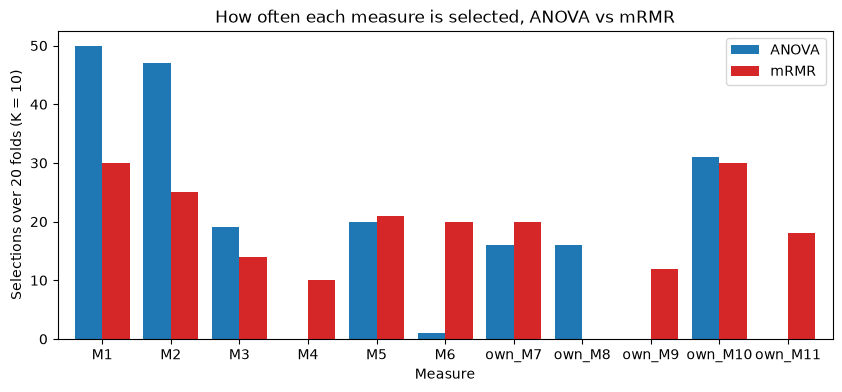

In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
counts_measure.plot.bar(ax=ax, color=["tab:blue", "tab:red"], width=0.8)
ax.set_xlabel("Measure")
ax.set_ylabel(f"Selections over 20 folds (K = {K})")
ax.set_title("How often each measure is selected, ANOVA vs mRMR")
ax.tick_params(axis="x", rotation=0)
plt.show()

### Relating to 3.4

In [24]:
corr = feature_table.corr()
corr_groups = []
for i, a in enumerate(feature_names):
    for b in feature_names[i + 1:]:
        if abs(corr.loc[a, b]) > 0.9:
            new = {a, b}
            touching = [g for g in corr_groups if g & new]
            for g in touching:
                corr_groups.remove(g)
                new = new | g
            corr_groups.append(new)
group_of = {f: i for i, g in enumerate(corr_groups) for f in g}

redundancy = {}
for name, folds in selected_per_fold.items():
    repeated = [len(chosen) - len({group_of.get(f, f) for f in chosen}) for chosen in folds]
    mean_r = [corr.loc[chosen, chosen].abs().to_numpy()[np.triu_indices(K, 1)].mean() for chosen in folds]
    redundancy[name] = {"distinct features over 20 folds": int((counts[name] > 0).sum()),
                        "features in all 20 folds": ", ".join(counts.index[counts[name] == 20]),
                        "repeated 3.4 groups per fold (mean)": round(np.mean(repeated), 2),
                        "mean |r| between selected features": round(np.mean(mean_r), 3)}
pd.DataFrame(redundancy)

,ANOVA,mRMR
distinct features over 20 folds,16,20
features in all 20 folds,"M1_vel, M2_mean, M2_vel, M5_mean, own_M10_vel","M1_mean, M2_mean, M5_mean, M6_mean, own_M7_mean"
repeated 3.4 groups per fold (mean),1.6,0.35
mean |r| between selected features,0.452,0.198


### Answer 5.5

**ANOVA concentrates on the mouth and on movement.** M1, M2, M3, M8 and M10, all mouth measures, take 163 of its 200 selections, and velocity and energy take 110. Five features are chosen in every fold: M2_mean, M5_mean, M2_vel, M1_vel and own_M10_vel. The brow measures (M4, M6, M9, M11) are chosen once in 20 folds. Because every video is speech, the mouth moves in all of them, and how much it moves differs strongly between emotions, so these features get the highest individual F-statistics.

**This is the redundancy predicted in 3.4.** ANOVA chooses M1_vel in 20 folds, own_M8_vel in 16 and M1_energy in 13: three features of group G1, which carry almost the same information. On average 1.6 of its 10 features share a 3.4 group with another selected feature, and the mean |r| between its selected features is 0.45.

**mRMR spreads its choices.** It uses 20 different features against 16, with only 0.35 repeated groups per fold and a mean |r| of 0.20. Once M1 is selected, own_M8 is never chosen: from 3.4, its movement is almost the same as that of M1. It replaces the repeated movement features with positions and with the brows: M6_mean and own_M7_mean in every fold, own_M11_mean in 18 and own_M9_mean in 12. These features are weak on their own, so ANOVA ignores them, but they carry information the mouth does not have. This explains why mRMR scores better in 5.4, with the advantage growing as K grows.

mRMR does not remove redundancy completely: own_M10_std and own_M10_range are selected together in some folds. Its redundancy term is the mean correlation with all the features already chosen, so a feature that is highly correlated with one of them but not with the others can still be chosen.

Both methods keep M2_mean and M5_mean in every fold, so the width of the mouth and the opening of the eyes are the most robust features of the set.

## C Simplification Cost

`C = 1` was chosen in 4.6 with all 55 features. Pipelines with fewer features or with PCA may have a different best C, so fixing it may slightly penalise them. C was also chosen on the same 20 actors used here, so the Section 5 scores carry a little of the optimism of 4.5. Tuning C inside each fold for each pipeline would remove both effects, at a much greater cost.

## 5.6 Configuration Summary Table

In [30]:
results_table(list(loso_results))

,features,macro F1 mean,macro F1 std,accuracy mean
All (55),55,0.557425,0.145965,0.589167
Base (30),30,0.52537,0.133787,0.559167
PCA 75 %,8,0.462535,0.134818,0.500833
PCA 95 %,22–23,0.538472,0.151027,0.574167
ANOVA K=5,5,0.345485,0.127188,0.404167
ANOVA K=10,10,0.421546,0.11408,0.480833
ANOVA K=15,15,0.4286,0.129257,0.483333
mRMR K=5,5,0.365749,0.156925,0.421667
mRMR K=10,10,0.462224,0.15234,0.5175
mRMR K=15,15,0.493576,0.138554,0.540833
